# Regresja wielomianowa

**Plan notatnika:**
1. Intuicja
2. Dane nieliniowe
3. Model liniowy (niedouczenie)
4. Cechy wielomianowe – `PolynomialFeatures`
5. Pipeline: cechy wielomianowe + regresja
6. Dobór stopnia wielomianu
7. Podsumowanie

## 1. Intuicja

Gdy zależność między $x$ a $y$ nie jest linią prostą, możemy dodać cechy wielomianowe ($x^2$, $x^3$, ...). Model **nadal jest liniowy względem parametrów**, ale opisuje krzywe:

$$y = w_0 + w_1 x + w_2 x^2 + w_3 x^3$$

Oznaczmy $z_1 = x$, $z_2 = x^2$, $z_3 = x^3$. Wtedy $y = w_0 + w_1 z_1 + w_2 z_2 + w_3 z_3$ – zwykła regresja liniowa na nowych cechach. Zmieniamy **reprezentację cech**, a nie algorytm.

Porównamy modele o stopniach 1, 2, 3 (i bardzo wysokim) na danych nieliniowych.

## 2. Dane nieliniowe

Generujemy dane z zależności sześciennej $y = -x^3 + 10x^2 - 2x + 3$ z szumem. Dzielimy je na zbiór treningowy i testowy.

Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 3 ("axes.prop_cycle: cycler('color', ['#123D98', '#C21E3C', '#E2A713', '#00AEEF', '#7F3F98'])"): Key axes.prop_cycle: "cycler('color', ['" is not a valid cycler construction: Could not parse "cycler('color', ['": unterminated string literal (detected at line 1) (<unknown>, line 1)
Bad value in file PosixPath('/Users/tomasz/.matplotlib/stylelib/company.mplstyle'), line 6 ('grid.color: #e0e0e0'): Key grid.color: '' does not look like a color arg


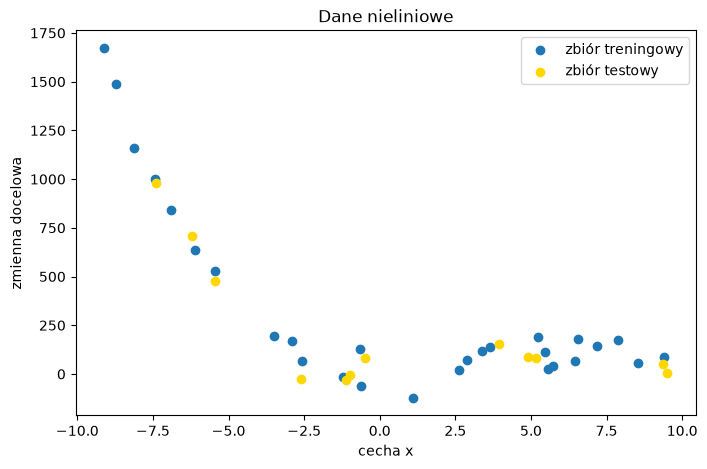

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)

X = np.sort(rng.uniform(-10, 10, 40)).reshape(-1, 1)
x = X[:, 0]
y = -x**3 + 10 * x**2 - 2 * x + 3 + rng.normal(0, 80, 40)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label='zbiór treningowy')
plt.scatter(X_test, y_test, color='gold', label='zbiór testowy')
plt.title('Dane nieliniowe')
plt.xlabel('cecha x')
plt.ylabel('zmienna docelowa')
plt.legend()
plt.show()

## 3. Model liniowy (niedouczenie)

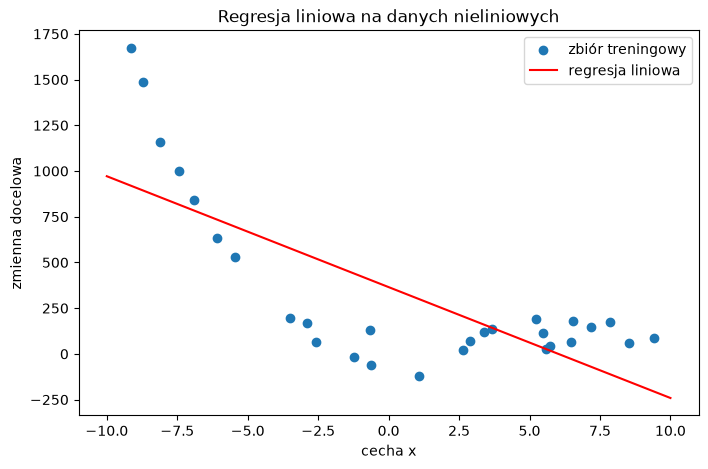

R2 train: 0.565
R2 test:  0.173


In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

regressor = LinearRegression()
regressor.fit(X_train, y_train)

X_grid = np.linspace(-10, 10, 300).reshape(-1, 1)    # gęsta siatka do rysowania krzywych

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label='zbiór treningowy')
plt.plot(X_grid, regressor.predict(X_grid), color='red', label='regresja liniowa')
plt.title('Regresja liniowa na danych nieliniowych')
plt.xlabel('cecha x')
plt.ylabel('zmienna docelowa')
plt.legend()
plt.show()

print(f'R2 train: {r2_score(y_train, regressor.predict(X_train)):.3f}')
print(f'R2 test:  {r2_score(y_test, regressor.predict(X_test)):.3f}')

Prosta nie uchwyca krzywizny: model jest **niedouczony** (*underfitting*), a błąd jest duży zarówno na zbiorze treningowym, jak i testowym.

## 4. Cechy wielomianowe – `PolynomialFeatures`

`PolynomialFeatures(degree=2)` dodaje do cech kolejne potęgi $x$: kolumny $1$, $x$, $x^2$.

In [3]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X_train)

pd.DataFrame(X_poly, columns=poly.get_feature_names_out(['x'])).head()

,1,x,x^2
0,1.0,-2.584040,6.677260
1,1.0,5.721286,32.733115
2,1.0,7.171958,51.436987
3,1.0,-5.461813,29.831401
4,1.0,-0.665580,0.442997


Dla **wielu cech** transformer tworzy także iloczyny cech. Przykład dla jednej obserwacji z cechami $a = 2$ i $b = 3$:

In [4]:
poly_ab = PolynomialFeatures(degree=2)
wynik = poly_ab.fit_transform([[2, 3]])

pd.DataFrame(wynik, columns=poly_ab.get_feature_names_out(['a', 'b']))

,1,a,b,a^2,a b,b^2
0,1.0,2.0,3.0,4.0,6.0,9.0


Liczba cech rośnie szybko wraz ze stopniem i liczbą cech, dlatego wysokich stopni używamy ostrożnie.

## 5. Pipeline: cechy wielomianowe + regresja

Cechy wielomianowe i model łączymy w `Pipeline`. Pomiędzy nimi dodajemy `StandardScaler`, bo wysokie potęgi $x$ (np. $x^{12}$) mają ogromne wartości i powodują problemy numeryczne. `include_bias=False` pomija kolumnę jedynek (model dodaje wyraz wolny sam).

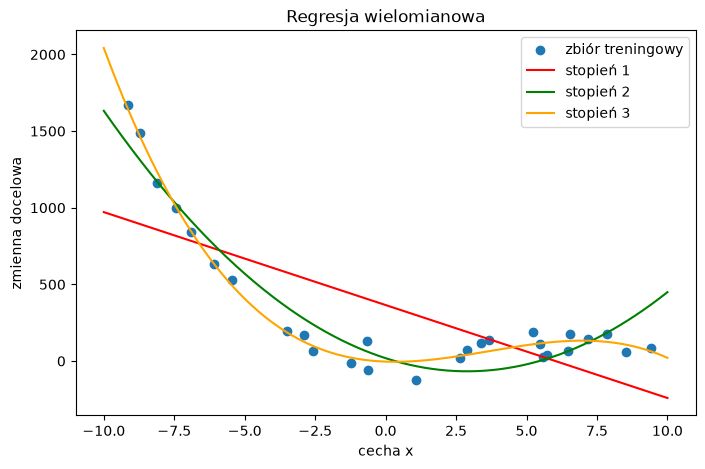

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def model_wielomianowy(degree):
    return make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression(),
    )

model_2 = model_wielomianowy(2).fit(X_train, y_train)
model_3 = model_wielomianowy(3).fit(X_train, y_train)

plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, label='zbiór treningowy')
plt.plot(X_grid, regressor.predict(X_grid), color='red', label='stopień 1')
plt.plot(X_grid, model_2.predict(X_grid), color='green', label='stopień 2')
plt.plot(X_grid, model_3.predict(X_grid), color='orange', label='stopień 3')
plt.title('Regresja wielomianowa')
plt.xlabel('cecha x')
plt.ylabel('zmienna docelowa')
plt.legend()
plt.show()

## 6. Dobór stopnia wielomianu

Porównajmy stopnie 1, 2, 3 oraz 12 na zbiorze treningowym **i testowym**.

In [6]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

wyniki = []
modele = {}
for degree in [1, 2, 3, 12]:
    m = model_wielomianowy(degree).fit(X_train, y_train)
    modele[degree] = m
    wyniki.append({
        'stopień': degree,
        'R2 train': r2_score(y_train, m.predict(X_train)),
        'R2 test': r2_score(y_test, m.predict(X_test)),
        'RMSE train': root_mean_squared_error(y_train, m.predict(X_train)),
        'RMSE test': root_mean_squared_error(y_test, m.predict(X_test)),
    })

pd.DataFrame(wyniki).set_index('stopień').round(3)

,R2 train,R2 test,RMSE train,RMSE test
stopień,,,,
1,0.565,0.173,307.281,286.797
2,0.913,0.637,137.388,189.857
3,0.985,0.968,57.153,55.987
12,0.992,0.918,42.853,90.552


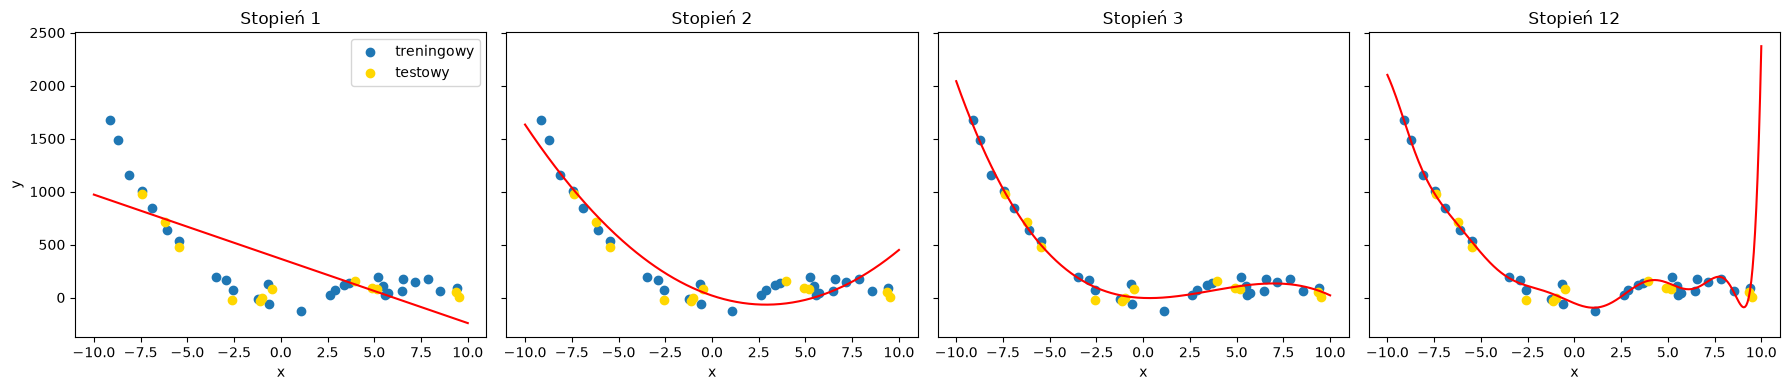

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)

for ax, (degree, m) in zip(axes, modele.items()):
    ax.scatter(X_train, y_train, label='treningowy')
    ax.scatter(X_test, y_test, color='gold', label='testowy')
    ax.plot(X_grid, m.predict(X_grid), color='red')
    ax.set_title(f'Stopień {degree}')
    ax.set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].legend()

plt.tight_layout()
plt.show()

**Jak czytać wyniki:**
- **Stopień 1** – niedouczenie: słabo na treningu i na teście.
- **Stopień 2** – lepiej, ale nadal nie oddaje kształtu.
- **Stopień 3** – dobry wynik na obu zbiorach (dane pochodzą z zależności sześciennej).
- **Stopień 12** – na zbiorze treningowym wynik jest najlepszy (krzywa „ugina się” do punktów), ale na testowym **gorszy** niż dla stopnia 3. To **przeuczenie** (*overfitting*).

Wynik na zbiorze treningowym zawsze poprawia się ze wzrostem stopnia, dlatego **modele wybieramy na podstawie zbioru testowego** (lub walidacji krzyżowej). Szerzej o niedouczeniu i przeuczeniu mówi rozdział 4.3.

## 7. Podsumowanie

1. Regresja wielomianowa to regresja liniowa na cechach $x, x^2, x^3, \ldots$ (`PolynomialFeatures`).
2. Pozwala opisać krzywe, a algorytm uczenia pozostaje ten sam.
3. Zbyt niski stopień prowadzi do niedouczenia, zbyt wysoki do przeuczenia.
4. Stopień wybieramy na podstawie wyników na danych, których model nie widział podczas treningu.
5. Dobra praktyka: najprostszy model o satysfakcjonującej jakości. Przy wysokich stopniach skalujemy cechy.